In [8]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter, SuzukiTrotter
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.primitives import StatevectorEstimator

In [9]:
def tfim_hamiltonian(num_qubits, J=1.0, h=1.0):
    """Transverse-field Ising Hamiltonian on an open chain as a SparsePauliOp."""
    terms = []

    # Interaction terms: -J * Z_i Z_{i+1}
    for i in range(num_qubits - 1):
        pauli = ["I"] * num_qubits
        pauli[i] = "Z"
        pauli[i + 1] = "Z"
        # Qiskit reads Pauli strings right-to-left (qubit 0 is the rightmost char)
        terms.append(("".join(reversed(pauli)), -J))

    # Field terms: -h * X_i
    for i in range(num_qubits):
        pauli = ["I"] * num_qubits
        pauli[i] = "X"
        terms.append(("".join(reversed(pauli)), -h))

    return SparsePauliOp.from_list(terms)


num_qubits = 4
J, h = 1.0, 1.0
H = tfim_hamiltonian(num_qubits, J, h)

print(f"TFIM on {num_qubits} qubits (J={J}, h={h}):")
print(H)

TFIM on 4 qubits (J=1.0, h=1.0):
SparsePauliOp(['IIZZ', 'IZZI', 'ZZII', 'IIIX', 'IIXI', 'IXII', 'XIII'],
              coeffs=[-1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j])


One Trotter step (dt=0.2):  depth = 10, 2-qubit gates = 6


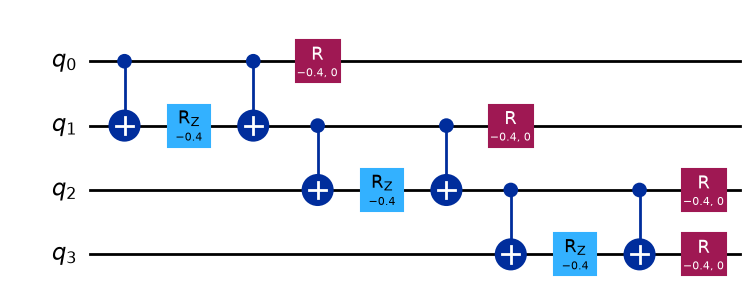

In [10]:
# A single Trotter step for a small time dt, using the first-order Lie-Trotter formula.
dt = 0.2
single_step = PauliEvolutionGate(H, time=dt, synthesis=LieTrotter(reps=1))

demo = QuantumCircuit(num_qubits)
demo.append(single_step, range(num_qubits))
demo = demo.decompose(reps=2)  # unroll into elementary gates so we can see them

print(f"One Trotter step (dt={dt}):  depth = {demo.depth()}, "
      f"2-qubit gates = {demo.num_nonlocal_gates()}")
demo.draw("mpl", fold=-1)

Circuit for t = 1.0


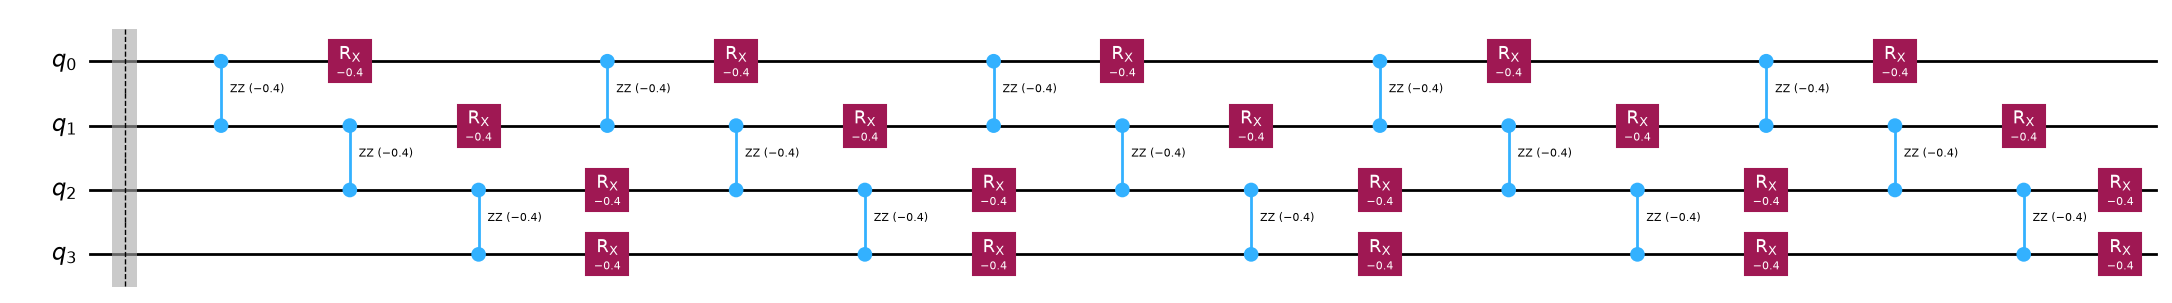

In [11]:
def trotter_evolution_circuit(H, num_qubits, dt, n_steps, order=1):
    """Prepare |00..0> and apply n_steps Trotter steps of size dt."""
    if order == 1:
        synth = LieTrotter(reps=1)
    else:
        synth = SuzukiTrotter(order=order, reps=1)

    qc = QuantumCircuit(num_qubits)
    # initial state |00..0> is the default; add an explicit barrier for clarity
    qc.barrier()

    step = PauliEvolutionGate(H, time=dt, synthesis=synth)
    for _ in range(n_steps):
        qc.append(step, range(num_qubits))

    return qc.decompose() # change to qc if needed --------------------------


# Example: 5 steps of size dt reaches time t = 5*dt
example = trotter_evolution_circuit(H, num_qubits, dt=0.2, n_steps=5)
print("Circuit for t =", 5 * 0.2)
example.draw("mpl", fold=-1)

In [12]:
def magnetization_op(num_qubits):
    """(1/N) * sum_i Z_i as a SparsePauliOp."""
    terms = []
    for i in range(num_qubits):
        pauli = ["I"] * num_qubits
        pauli[i] = "Z"
        terms.append(("".join(reversed(pauli)), 1.0 / num_qubits))
    return SparsePauliOp.from_list(terms)


Mz = magnetization_op(num_qubits)
estimator = StatevectorEstimator()

# --- Trotterized evolution ---
dt = 0.15
max_steps = 10
times = np.array([n * dt for n in range(max_steps + 1)])

mz_trotter = []
for n in range(max_steps + 1):
    circ = trotter_evolution_circuit(H, num_qubits, dt=dt, n_steps=n)
    result = estimator.run([(circ, Mz)]).result()
    mz_trotter.append(float(result[0].data.evs))
mz_trotter = np.array(mz_trotter)

In [13]:
# --- Exact reference evolution (classical, small systems only) ---
from scipy.linalg import expm

H_matrix = H.to_matrix()
Mz_matrix = Mz.to_matrix()
psi0 = Statevector.from_label("0" * num_qubits).data

mz_exact = []
for t in times:
    U = expm(-1j * H_matrix * t)
    psi_t = U @ psi0
    val = np.real(np.conj(psi_t) @ Mz_matrix @ psi_t)
    mz_exact.append(val)
mz_exact = np.array(mz_exact)

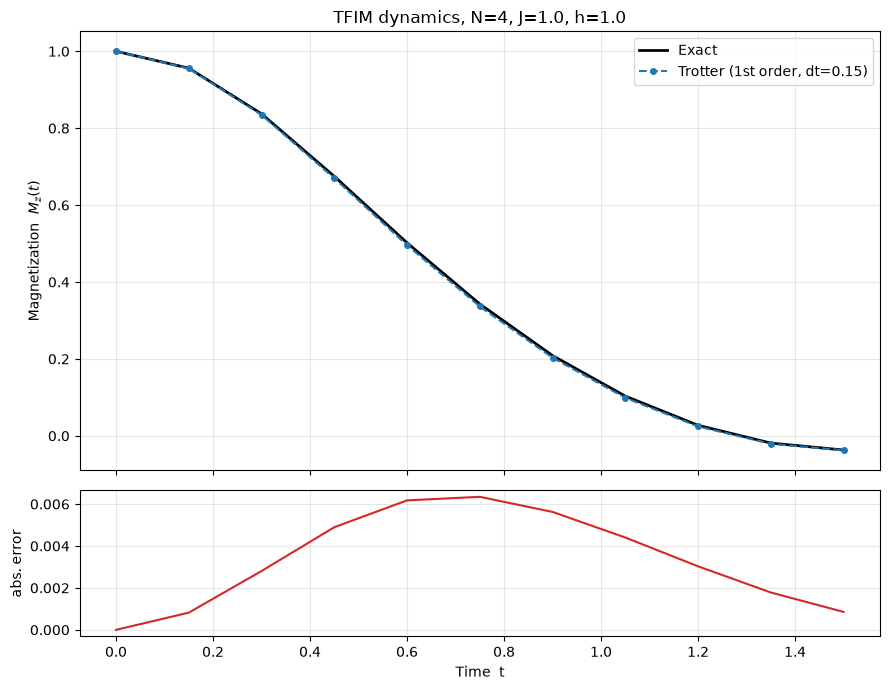

Max error over the trajectory: 0.0063


In [14]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})

ax1.plot(times, mz_exact, "k-", lw=2, label="Exact")
ax1.plot(times, mz_trotter, "o--", color="#1f77b4", ms=4,
         label=f"Trotter (1st order, dt={dt})")
ax1.set_ylabel(r"Magnetization  $M_z(t)$")
ax1.set_title(f"TFIM dynamics, N={num_qubits}, J={J}, h={h}")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(times, np.abs(mz_trotter - mz_exact), color="#d62728")
ax2.set_xlabel("Time  t")
ax2.set_ylabel("abs. error")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Max error over the trajectory: {np.max(np.abs(mz_trotter - mz_exact)):.4f}")

In [15]:
from scipy.linalg import expm

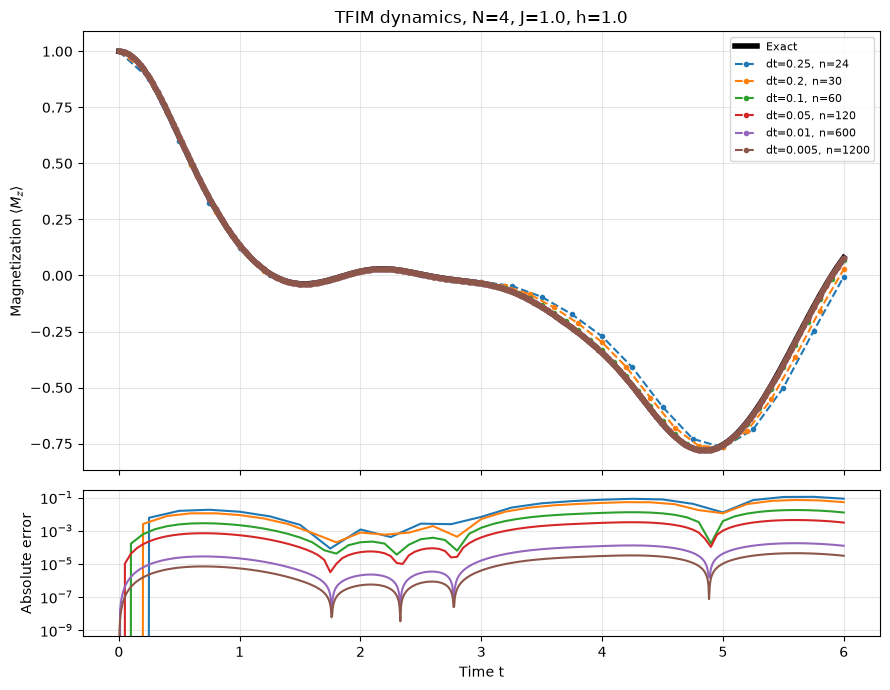

In [9]:
T = 6.0 
dt_vals = [0.25, 0.2, 0.1, 0.05, 0.01, 0.005]

H_matrix = H.to_matrix()
Mz_matrix = Mz.to_matrix()    
psi0 = Statevector.from_label("0" * num_qubits).data

def exact_magnetization(t):
    psi_t = expm(-1j * H_matrix * t) @ psi0
    return float(np.real(np.vdot(psi_t, Mz_matrix @ psi_t)))

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(9, 7), sharex=True, 
    gridspec_kw={"height_ratios": [3,1]}
)

exact_times = np.linspace(0, T, 201)
ax1.plot(exact_times, [exact_magnetization(t) for t in exact_times], "k-", lw=4, label="Exact")

results = {}

for dt in dt_vals:
    n_steps = int(round(T/dt))

    times = np.arange(n_steps + 1) * dt
    mz_trotter = []

    for k in range(n_steps + 1):
        circ = trotter_evolution_circuit(H, num_qubits, dt=dt, n_steps=k)
        result = estimator.run([(circ, Mz)]).result()
        mz_trotter.append(float(result[0].data.evs))

    mz_trotter = np.array(mz_trotter)
    mz_exact = np.array([exact_magnetization(t) for t in times])

    errors = np.abs(mz_trotter - mz_exact)

    results[dt] = {
        "times": times,
        "mz_trotter": mz_trotter,
        "mz_exact": mz_exact,
        "errors": errors
    }

    line, = ax1.plot(
        times, mz_trotter, "o--", ms=3, label=f"dt={dt:g}, n={n_steps}"
    )

    ax2.plot(times, errors, color=line.get_color())

ax1.set_ylabel(r"Magnetization $\langle M_z\rangle$")
ax1.set_title(f"TFIM dynamics, N={num_qubits}, J={J}, h={h}")
ax1.legend(fontsize=8)

ax2.set_xlabel("Time t")
ax2.set_ylabel("Absolute error")
ax2.set_yscale("log")

for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

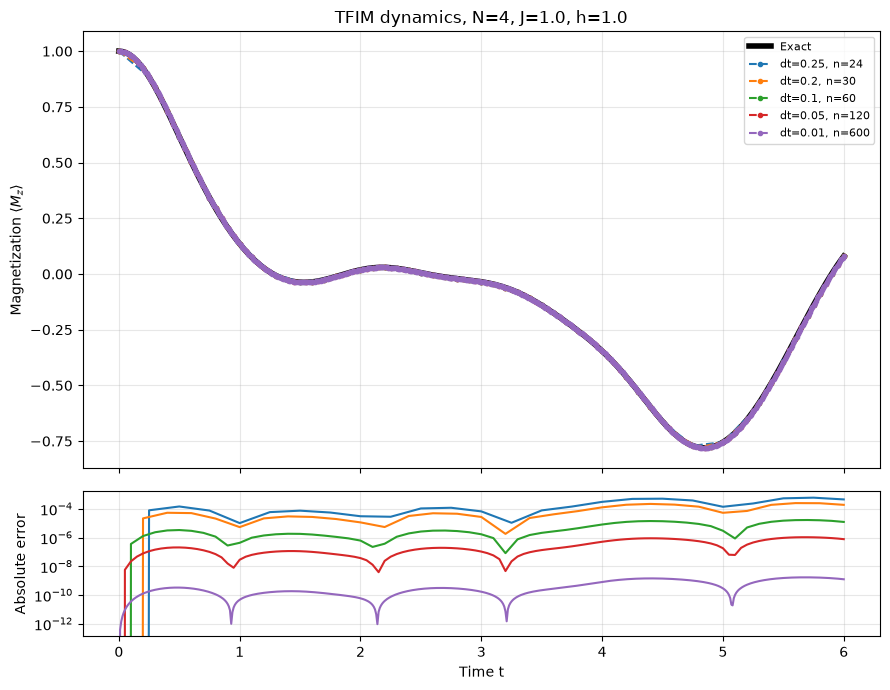

In [10]:
T = 6.0 
dt_vals = [0.25, 0.2, 0.1, 0.05, 0.01]

H_matrix = H.to_matrix()
Mz_matrix = Mz.to_matrix()    
psi0 = Statevector.from_label("0" * num_qubits).data

def exact_magnetization(t):
    psi_t = expm(-1j * H_matrix * t) @ psi0
    return float(np.real(np.vdot(psi_t, Mz_matrix @ psi_t)))

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(9, 7), sharex=True, 
    gridspec_kw={"height_ratios": [3,1]}
)

exact_times = np.linspace(0, T, 201)
ax1.plot(exact_times, [exact_magnetization(t) for t in exact_times], "k-", lw=4, label="Exact")

results = {}

for dt in dt_vals:
    n_steps = int(round(T/dt))

    times = np.arange(n_steps + 1) * dt
    mz_trotter = []

    for k in range(n_steps + 1):
        circ = trotter_evolution_circuit(H, num_qubits, dt=dt, n_steps=k, order=4)
        result = estimator.run([(circ, Mz)]).result()
        mz_trotter.append(float(result[0].data.evs))

    mz_trotter = np.array(mz_trotter)
    mz_exact = np.array([exact_magnetization(t) for t in times])

    errors = np.abs(mz_trotter - mz_exact)

    results[dt] = {
        "times": times,
        "mz_trotter": mz_trotter,
        "mz_exact": mz_exact,
        "errors": errors
    }

    line, = ax1.plot(
        times, mz_trotter, "o--", ms=3, label=f"dt={dt:g}, n={n_steps}"
    )

    ax2.plot(times, errors, color=line.get_color())

ax1.set_ylabel(r"Magnetization $\langle M_z\rangle$")
ax1.set_title(f"TFIM dynamics, N={num_qubits}, J={J}, h={h}")
ax1.legend(fontsize=8)

ax2.set_xlabel("Time t")
ax2.set_ylabel("Absolute error")
ax2.set_yscale("log")

for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

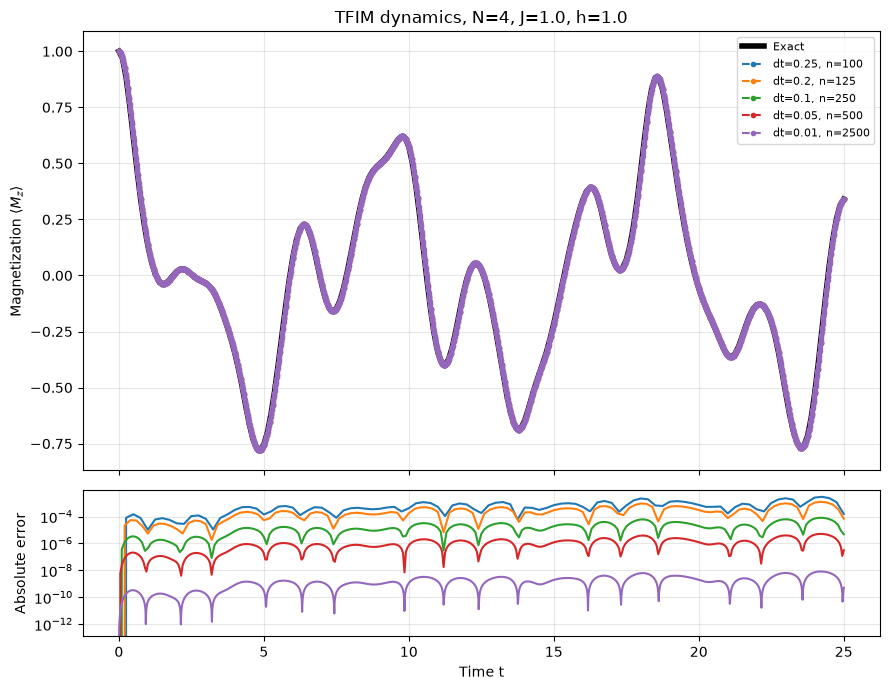

In [11]:
# 4th order Suzuki Trotter

T = 25 
dt_vals = [0.25, 0.2, 0.1, 0.05, 0.01]

H_matrix = H.to_matrix()
Mz_matrix = Mz.to_matrix()    
psi0 = Statevector.from_label("0" * num_qubits).data

def exact_magnetization(t):
    psi_t = expm(-1j * H_matrix * t) @ psi0
    return float(np.real(np.vdot(psi_t, Mz_matrix @ psi_t)))

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(9, 7), sharex=True, 
    gridspec_kw={"height_ratios": [3,1]}
)

exact_times = np.linspace(0, T, 201)
ax1.plot(exact_times, [exact_magnetization(t) for t in exact_times], "k-", lw=4, label="Exact")

results = {}

for dt in dt_vals:
    n_steps = int(round(T/dt))

    times = np.arange(n_steps + 1) * dt
    mz_trotter = []

    for k in range(n_steps + 1):
        circ = trotter_evolution_circuit(H, num_qubits, dt=dt, n_steps=k, order=4)
        result = estimator.run([(circ, Mz)]).result()
        mz_trotter.append(float(result[0].data.evs))

    mz_trotter = np.array(mz_trotter)
    mz_exact = np.array([exact_magnetization(t) for t in times])

    errors = np.abs(mz_trotter - mz_exact)

    results[dt] = {
        "times": times,
        "mz_trotter": mz_trotter,
        "mz_exact": mz_exact,
        "errors": errors
    }

    line, = ax1.plot(
        times, mz_trotter, "o--", ms=3, label=f"dt={dt:g}, n={n_steps}"
    )

    ax2.plot(times, errors, color=line.get_color())

ax1.set_ylabel(r"Magnetization $\langle M_z\rangle$")
ax1.set_title(f"TFIM dynamics, N={num_qubits}, J={J}, h={h}")
ax1.legend(fontsize=8)

ax2.set_xlabel("Time t")
ax2.set_ylabel("Absolute error")
ax2.set_yscale("log")

for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()